# P02: which features tell pine from eucalyptus?

**Question.** Among plantations in PR, SC and RS, which satellite features separate **pine** from
**eucalyptus**? Do the new **rotation-length** features (eucalyptus is clear-cut about every 6–8 years,
pine about every 12–25 years with thinnings) add anything?

**Data.**
- **Points:** MapBiomas reference points labelled plantation, **development split only**. The lockbox
  split is kept untouched for the final test of the P03 model.
- **Features:** the shared master feature table v3 (`Master Data/`), AlphaEarth embeddings, and new
  rotation features built from the public yearly Landsat NBR series (`public_data/harvest_cycles/`).
- **Species labels:** WRI's Spatial Database of Planted Trees (SDPT v2.0). The polygons come from
  Petersen et al. (2016), with **2013–14 imagery**. A point is labelled only if it lies **inside** a
  polygon whose species is *Pinus* or *Eucalyptus*. See `pine_detection/docs/sdpt_check.md`.

**Caveats.**
- These are *silver* labels: about 12 years old and never checked by us. A stand may have been replanted
  with the other genus since.
- Pine and eucalyptus aren't spread evenly across the region (pine dominates the SC/PR highlands), so any
  feature that tracks region will look useful. Section 5 checks this.
- Everything here is exploratory.

**How to read the numbers.**
- **AUC:** the chance that a randomly picked eucalyptus point scores higher than a randomly picked pine
  point (or lower, whichever direction the feature goes). 0.5 is a coin flip and 1.0 is perfect
  separation. The table shows the direction.
- **95% CI:** bootstrap range of the AUC (2,000 resamples). The true value is probably in this range.
- **Mann–Whitney p:** chance of a difference this large between the two species if the feature didn't
  differ at all.
- **Holm p:** the same p, corrected because many features are tested at once.
- **Spatially blocked cross-validation (CV):** the model is trained on some regions and tested on others,
  using 20 location clusters. This stops it scoring well just by memorizing nearby points.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", message=".*matmul.*")
warnings.filterwarnings("ignore", category=RuntimeWarning)

PD = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pine_detection" / "src").exists()) / "pine_detection"
sys.path.insert(0, str(PD / "src"))
import species_features as sf
qa = sf.qa
qa.set_style()
PAL = sf.PAL_SPECIES
RES = PD / "results"; RES.mkdir(exist_ok=True)
pd.set_option("display.width", 160)

## 1. Species labels on the MapBiomas plantation points

In [2]:
m = sf.add_sdpt(sf.load_master())
plant = m[m.label == 1]
print("MapBiomas plantation points by SDPT species (inside a polygon) and split:")
display(pd.crosstab(plant.species, plant.split, margins=True))
print("\nDevelopment split, by state:")
display(pd.crosstab(plant[plant.split == "dev"].species, plant[plant.split == "dev"].state, margins=True))
print(f"\nMapBiomas forest points inside an SDPT polygon: {(m[m.label == 0].species != 'none').sum()} "
      f"of {(m.label == 0).sum()}")

MapBiomas plantation points by SDPT species (inside a polygon) and split:


split,dev,lockbox,All
species,,,
acacia,4,3,7
eucalyptus,85,17,102
none,152,40,192
pine,160,39,199
unknown,10,3,13
All,411,102,513



Development split, by state:


state,PR,RS,SC,All
species,,,,
acacia,0,4,0,4
eucalyptus,17,31,37,85
none,53,56,43,152
pine,58,30,72,160
unknown,7,0,3,10
All,135,121,155,411



MapBiomas forest points inside an SDPT polygon: 35 of 1740


In [3]:
d = plant[(plant.split == "dev") & plant.species.isin(["pine", "eucalyptus"])].copy()
d["y"] = (d.species == "eucalyptus").astype(int)       # 1 = eucalyptus, 0 = pine
print(f"Analysis sample: {len(d)} points ({d.y.sum()} eucalyptus, {(1 - d.y).sum()} pine), "
      f"{d.train_eligible.mean():.0%} train-eligible in the combined model's sense")

Analysis sample: 245 points (85 eucalyptus, 160 pine), 82% train-eligible in the combined model's sense


## 2. New rotation features from the yearly NBR series

**NBR** (Normalized Burn Ratio) is high under a closed canopy and drops sharply when trees are cut. For
each year from 2000 to 2020 we compare NBR with its level in the two previous years. These rules were
fixed before looking at species:
- **clear-cut:** NBR falls by at least 0.20, at least 3 years after the previous clear-cut;
- **partial drop:** NBR falls by 0.08–0.20 and is not next to a clear-cut. This is a thinning candidate,
  since pine is usually thinned 2–3 times per rotation.

From these we compute the number of clear-cuts, the median years between clear-cuts, the years since the
last clear-cut, the number of partial drops, and partial drops per clear-cut.

In [4]:
nbr = sf.load_nbr(d.team_pid)
rot = sf.rotation_features(nbr)
rot.index = d.index
d = d.join(rot)
has = nbr.notna().sum(axis=1).to_numpy() >= 15
d.loc[~has, rot.columns] = np.nan                       # too few clear years: leave missing
print(f"NBR series available (>= 15 of 21 years) for {has.mean():.0%} of the sample "
      f"({has[d.y.to_numpy() == 1].mean():.0%} of eucalyptus, {has[d.y.to_numpy() == 0].mean():.0%} of pine)")
display(d.groupby("species")[list(rot.columns)].median().T.round(1))

NBR series available (>= 15 of 21 years) for 85% of the sample (87% of eucalyptus, 84% of pine)


species,eucalyptus,pine
rot_n_cuts,1.0,1.0
rot_med_interval,11.0,11.0
rot_years_since,12.0,11.0
rot_n_partial,1.0,1.0
rot_partial_per_cut,0.7,0.7


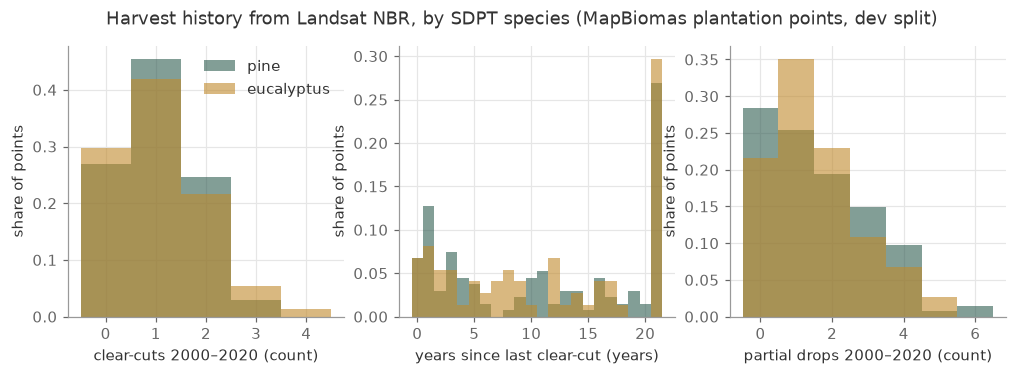

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, col, lab in zip(axes, ["rot_n_cuts", "rot_years_since", "rot_n_partial"],
                        ["clear-cuts 2000–2020 (count)", "years since last clear-cut (years)",
                         "partial drops 2000–2020 (count)"]):
    bins = np.arange(-0.5, d[col].max() + 1.5, 1)
    for sp in ["pine", "eucalyptus"]:
        ax.hist(d.loc[d.species == sp, col].dropna(), bins=bins, density=True, alpha=0.6,
                color=PAL[sp], label=sp)
    ax.set_xlabel(lab); ax.set_ylabel("share of points")
axes[0].legend()
fig.suptitle("Harvest history from Landsat NBR, by SDPT species (MapBiomas plantation points, dev split)")
sf.savefig(fig, "P02_rotation_distributions")

## 3. One feature at a time

In [6]:
cols = pd.read_csv(PD.parent / "combined_model/docs/v3_columns.csv")
master_feats = cols.loc[cols.role.isin(["feature", "benchmark"]), "column"].tolist()
rot_feats = list(rot.columns)
geo_feats = ["lat", "lon"]
FAMILY = {}
for c in master_feats + rot_feats + geo_feats:
    FAMILY[c] = ("Rotation (new)" if c.startswith("rot_") else "Geography" if c in geo_feats else
                 "Spectral / seasonal" if c.startswith(("nc_B_", "nc_wi", "nc_su", "nc_sg", "mm_", "nc_A_")) else
                 "Structure / radar" if c.startswith(("nc_E_", "nc_F_", "nc_chm")) else
                 "History / maps")
NAMES = {
    "nc_B_SAG_SON": "SAG Sep–Nov", "nc_B_SAG_phase_sin": "SAG seasonal timing", "mm_SAG_win": "SAG winter",
    "nc_wi3_NDMI": "NDMI winter", "nc_su3_NDMI": "NDMI summer", "nc_sg3_NDVI": "NDVI seasonal range",
    "mm_NDVI_win": "NDVI winter", "mm_B6_win": "B6 red-edge winter", "mm_B8A_win": "B8A narrow NIR winter",
    "nc_B_NDRE_phase_sin": "NDRE seasonal timing", "nc_B_SWIR_phase_sin": "SWIR seasonal timing (sin)",
    "nc_B_SWIR_phase_cos": "SWIR seasonal timing (cos)", "nc_E_eth_h": "canopy height (ETH)",
    "nc_E_eth_sd50": "canopy height variability", "nc_F_VHminusVV_median": "radar VH − VV",
    "nc_F_VH_median": "radar VH", "nc_D_max_nbr_drop": "largest NBR drop", "nc_D_cc_n_breaks": "CCDC breaks",
    "nc_D_years_continuous_forest": "years of continuous forest", "nc_D_lt_n_vertices": "LandTrendr vertices",
    "nc_D_ndvi_1985_89": "NDVI 1985–89", "nc_D_h_total_loss_px": "Hansen loss within 150 m",
    "nc_nfw": "Natural Forests of the World", "nc_H_mapbiomas10m_plantation": "MapBiomas 10 m plantation",
    "rh_n_cycles": "harvest cycles (team)", "rh_s_std": "NBR variability (team)",
    "rh_s_frac_below_forest": "share of years below canopy", "rh_abrupt_start": "abrupt start on open land",
    "nc_hansen_tc2000": "Hansen tree cover 2000", "lh_natural_run_years": "years of natural cover (MapBiomas)",
    "lh_n_changes": "land-cover changes (MapBiomas)", "lh_ever_open": "ever open land (MapBiomas)",
    "nc_A_SAG": "SAG Oct–Jan (Cropin)", "nc_chm_mean_r15": "canopy height (Meta 1 m)",
    "nc_chm_stdDev_r15": "canopy height variability (Meta 1 m)",
    "rot_n_cuts": "clear-cuts 2000–20 (new)", "rot_med_interval": "years between clear-cuts (new)",
    "rot_years_since": "years since last clear-cut (new)", "rot_n_partial": "partial drops (new)",
    "rot_partial_per_cut": "partial drops per clear-cut (new)", "lat": "latitude", "lon": "longitude",
}

rows = []
for c in master_feats + rot_feats + geo_feats:
    s = d[[c, "y"]].dropna()
    if s[c].nunique() < 2 or s.y.nunique() < 2:
        continue
    auc, lo, hi = qa.auc_ci(s.y, s[c])
    raw = roc_auc_score(s.y, s[c])
    rows.append(dict(feature=NAMES.get(c, c), column=c, family=FAMILY[c], n=len(s),
                     median_pine=s.loc[s.y == 0, c].median(), median_eucalyptus=s.loc[s.y == 1, c].median(),
                     AUC=auc, CI_lo=lo, CI_hi=hi,
                     direction="higher in eucalyptus" if raw >= 0.5 else "higher in pine",
                     p_MWU=qa.mwu_test(s.loc[s.y == 1, c], s.loc[s.y == 0, c])))
uni = pd.DataFrame(rows)
uni["p_Holm"] = qa.holm(uni.p_MWU)
uni = uni.sort_values("AUC", ascending=False).reset_index(drop=True)
uni.to_csv(RES / "P02_univariate.csv", index=False)
show = uni.drop(columns="column").copy()
show["AUC [95% CI]"] = [f"{a:.2f} [{l:.2f}–{h:.2f}]" for a, l, h in zip(uni.AUC, uni.CI_lo, uni.CI_hi)]
show = show.drop(columns=["AUC", "CI_lo", "CI_hi"])
show["p_MWU"] = show.p_MWU.map(lambda p: f"{p:.1g}"); show["p_Holm"] = show.p_Holm.map(lambda p: f"{p:.1g}")
show[["median_pine", "median_eucalyptus"]] = show[["median_pine", "median_eucalyptus"]].round(3)
show

,feature,family,n,median_pine,median_eucalyptus,direction,p_MWU,p_Holm,AUC [95% CI]
0,latitude,Geography,245,-26.659,-27.766,higher in pine,0.0002,0.008,0.64 [0.57–0.72]
1,share of years below canopy,History / maps,245,0.329,0.474,higher in eucalyptus,0.007,0.3,0.60 [0.53–0.68]
2,NDVI 1985–89,History / maps,245,0.679,0.639,higher in pine,0.06,1,0.57 [0.50–0.65]
3,Hansen tree cover 2000,History / maps,245,66.500,47.000,higher in pine,0.07,1,0.57 [0.50–0.65]
4,B8A narrow NIR winter,Spectral / seasonal,245,0.245,0.258,higher in eucalyptus,0.07,1,0.57 [0.49–0.64]
5,canopy height variability,Structure / radar,245,1.584,1.341,higher in pine,0.08,1,0.57 [0.49–0.65]
6,B6 red-edge winter,Spectral / seasonal,245,0.178,0.183,higher in eucalyptus,0.1,1,0.56 [0.49–0.64]
7,LandTrendr vertices,History / maps,245,3.000,2.000,higher in pine,0.1,1,0.55 [0.48–0.63]
8,years of continuous forest,History / maps,245,14.000,13.000,higher in pine,0.3,1,0.54 [0.47–0.62]
9,NDVI winter,Spectral / seasonal,245,0.842,0.853,higher in eucalyptus,0.3,1,0.54 [0.46–0.62]


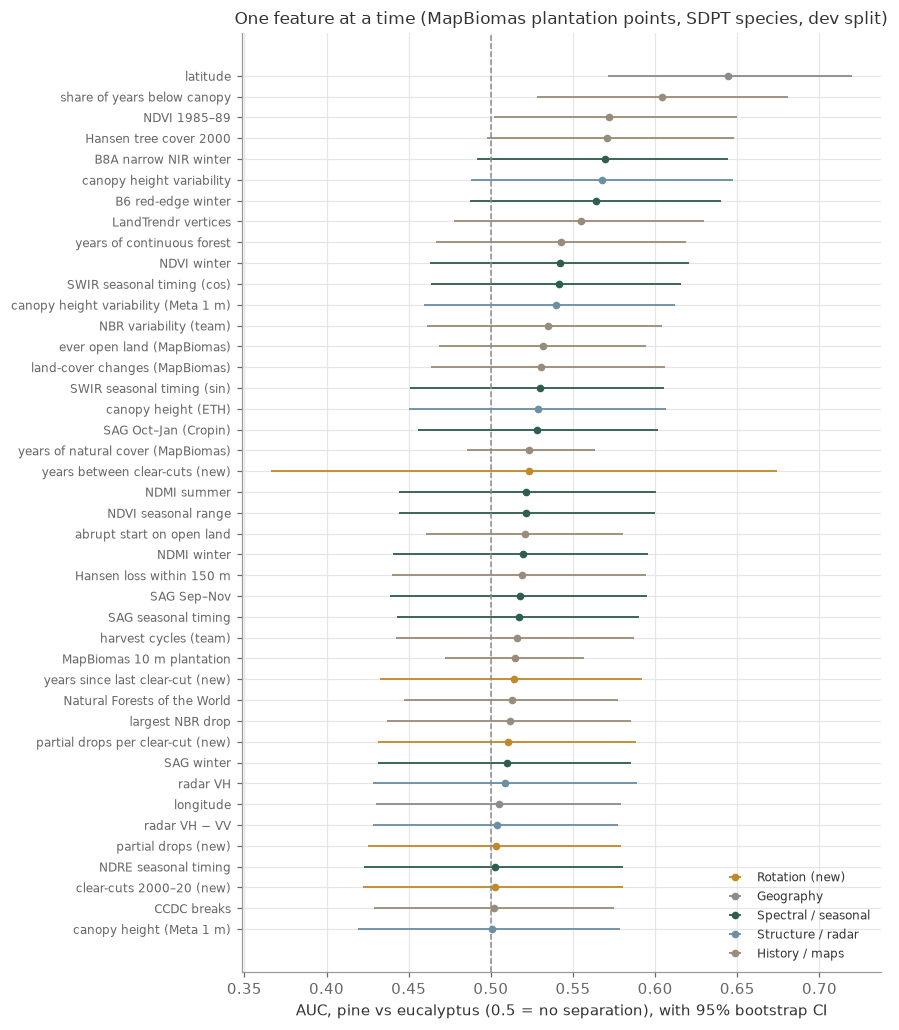

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 0.24 * len(uni) + 1))
fam_col = {"Rotation (new)": PAL["eucalyptus"], "Geography": PAL["grey"], "Spectral / seasonal": PAL["pine"],
           "Structure / radar": "#6B8FA3", "History / maps": "#9A8C7A"}
yy = np.arange(len(uni))[::-1]
for fam, col in fam_col.items():
    k = uni.family == fam
    ax.errorbar(uni.AUC[k], yy[k], xerr=[uni.AUC[k] - uni.CI_lo[k], uni.CI_hi[k] - uni.AUC[k]],
                fmt="o", color=col, ms=4, lw=1.2, label=fam)
ax.axvline(0.5, color=PAL["grey"], lw=1, ls="--")
ax.set_yticks(yy); ax.set_yticklabels(uni.feature, fontsize=8)
ax.set_xlabel("AUC, pine vs eucalyptus (0.5 = no separation), with 95% bootstrap CI")
ax.legend(loc="lower right", fontsize=8)
ax.set_title("One feature at a time (MapBiomas plantation points, SDPT species, dev split)")
sf.savefig(fig, "P02_univariate_auc")

## 4. Feature families in a model (spatially blocked CV)

Each family goes into a logistic regression: missing values are filled with the median, and features are
standardized. Geography and all features are also fit with a random forest, because a straight line in
latitude/longitude can't capture a regional pattern. The AUC is out-of-fold, using 20 spatial blocks, and
the table shows the mean (and range) over seeds 0–19 (seeds 0–4 for the random forest).

In [8]:
ae_feats = [c for c in d.columns if c.startswith("ae_A")]
def logit():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=2000))
def forest():
    return make_pipeline(SimpleImputer(strategy="median"),
                         RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=0, n_jobs=-1))
families = {
    "Geography (lat, lon)": geo_feats,
    "Spectral / seasonal": [c for c in master_feats if FAMILY[c] == "Spectral / seasonal"],
    "Structure / radar": [c for c in master_feats if FAMILY[c] == "Structure / radar"],
    "History / maps (existing)": [c for c in master_feats if FAMILY[c] == "History / maps"],
    "Rotation (new)": rot_feats,
    "History / maps + rotation": [c for c in master_feats if FAMILY[c] == "History / maps"] + rot_feats,
    "AlphaEarth (64 dims)": ae_feats,
    "All master features + rotation": master_feats + rot_feats,
    "All + AlphaEarth": master_feats + rot_feats + ae_feats,
}
groups = qa.spatial_groups(d, k=20, seed=0)
y = d.y.to_numpy()
out = []
for name, fs in families.items():
    r, _ = qa.cv_evaluate(d[fs].to_numpy(float), y, groups=groups, kind="spatial", model_fn=logit)
    out.append(dict(family=name, model="logistic", n_features=len(fs), AUC=r.auc.mean(), AUC_min=r.auc.min(), AUC_max=r.auc.max()))
for name in ["Geography (lat, lon)", "All master features + rotation", "All + AlphaEarth"]:
    fs = families[name]
    r, _ = qa.cv_evaluate(d[fs].to_numpy(float), y, groups=groups, kind="spatial", seeds=range(5), model_fn=forest)
    out.append(dict(family=name, model="random forest", n_features=len(fs), AUC=r.auc.mean(), AUC_min=r.auc.min(), AUC_max=r.auc.max()))
fam = pd.DataFrame(out)
fam.to_csv(RES / "P02_families_cv.csv", index=False)
fam.round(3)

,family,model,n_features,AUC,AUC_min,AUC_max
0,"Geography (lat, lon)",logistic,2,0.540,0.504,0.569
1,Spectral / seasonal,logistic,13,0.438,0.396,0.476
2,Structure / radar,logistic,6,0.399,0.347,0.444
3,History / maps (existing),logistic,16,0.539,0.501,0.572
4,Rotation (new),logistic,5,0.369,0.352,0.397
5,History / maps + rotation,logistic,21,0.568,0.524,0.605
6,AlphaEarth (64 dims),logistic,64,0.481,0.440,0.560
7,All master features + rotation,logistic,40,0.509,0.464,0.545
8,All + AlphaEarth,logistic,104,0.515,0.445,0.577
9,"Geography (lat, lon)",random forest,2,0.509,0.489,0.530


## 5. Is it just geography? AUC within each state

If a feature only works because pine and eucalyptus grow in different regions, its AUC should fall toward
0.5 inside a single state. Below are the top 10 features (by overall AUC) plus latitude, in states with at
least 15 points of each species.

In [9]:
top = uni.column.head(10).tolist() + (["lat"] if "lat" not in uni.column.head(10).tolist() else [])
rows = []
for st, g in d.groupby("state"):
    if min(g.y.sum(), (1 - g.y).sum()) < 15:
        continue
    for c in top:
        s = g[[c, "y"]].dropna()
        a = roc_auc_score(s.y, s[c])
        rows.append(dict(state=f"{st} (eucalyptus {int(g.y.sum())}, pine {int((1 - g.y).sum())})",
                         feature=NAMES.get(c, c), AUC=max(a, 1 - a)))
within = pd.DataFrame(rows).pivot(index="feature", columns="state", values="AUC")
within.insert(0, "all states", uni.set_index("feature").AUC.reindex(within.index))
within.sort_values("all states", ascending=False).round(2)

state,all states,"PR (eucalyptus 17, pine 58)","RS (eucalyptus 31, pine 30)","SC (eucalyptus 37, pine 72)"
feature,,,,
latitude,0.64,0.74,0.68,0.63
share of years below canopy,0.60,0.62,0.58,0.66
NDVI 1985–89,0.57,0.71,0.51,0.68
Hansen tree cover 2000,0.57,0.56,0.51,0.62
B8A narrow NIR winter,0.57,0.61,0.67,0.51
canopy height variability,0.57,0.66,0.55,0.53
B6 red-edge winter,0.56,0.60,0.66,0.52
LandTrendr vertices,0.55,0.51,0.64,0.50
years of continuous forest,0.54,0.58,0.53,0.56


## 6. Sensitivity of the rotation features to the clear-cut rule

The same AUCs with the clear-cut threshold set to 0.15 and 0.25 instead of 0.20.

In [10]:
rows = []
for cut in [0.15, 0.20, 0.25]:
    rr = sf.rotation_features(nbr, cut=cut); rr.index = d.index
    rr.loc[~has] = np.nan
    for c in rr.columns:
        s = pd.concat([rr[c], d.y], axis=1).dropna()
        if s[c].nunique() > 1:
            a = roc_auc_score(s.y, s[c]); rows.append(dict(feature=NAMES[c], cut=cut, AUC=max(a, 1 - a)))
pd.DataFrame(rows).pivot(index="feature", columns="cut", values="AUC").round(2)

cut,0.15,0.20,0.25
feature,,,
clear-cuts 2000–20 (new),0.51,0.50,0.51
partial drops (new),0.52,0.50,0.52
partial drops per clear-cut (new),0.53,0.51,0.50
years between clear-cuts (new),0.54,0.52,0.61
years since last clear-cut (new),0.51,0.51,0.53


## 7. Summary (first run, 20 Nov 2026)

**Against SDPT's species labels, almost nothing separates pine from eucalyptus.**
- **Sample:** 245 MapBiomas plantation points (85 eucalyptus, 160 pine), development split.
- **One feature at a time:**
  - the best is **latitude** (AUC 0.64; eucalyptus lies further south). It is the only feature that
    survives the Holm correction;
  - the best satellite features are near-infrared and red-edge in winter (B8A and B6, higher in
    eucalyptus, as expected for broadleaf vs needles), but only at AUC 0.56–0.57, with CIs that touch 0.5.
- **The new rotation features don't work:** AUC 0.50–0.52. The median time between clear-cuts is 11
  years for both species. Eucalyptus should be about 6–8.
- **Models:** with spatially blocked CV, no family beats 0.57, and some fall below 0.5. This is what
  happens when there is no real signal.

**Why we think the labels are the problem, not the features:**
1. **The same features find this difference elsewhere.** Conifer and broadleaf canopies are known to differ
   in near-infrared, and the IPEF national mapping and a UDESC thesis in Santa Catarina both separate pine
   from eucalyptus with Sentinel-2. Here the expected direction appears, but only weakly.
2. **The rotation lengths are identical,** which shouldn't happen if the labels were right at the stand
   level.
3. **The labels date from 2013–14 and come from one compilation** (Petersen et al. 2016) with no accuracy
   assessment. 35 MapBiomas *forest* points also fall inside SDPT polygons.
4. **Latitude separates the species,** so SDPT seems right at the **regional** level (pine in the north
   and highlands, eucalyptus further south) but not at the level of individual **stands**.

**What it means:**
- SDPT alone shouldn't be used to train or evaluate a species model.
- The hand-labelled gold set (PLAN §2.2) is now the critical path. Its first job is to measure how often
  SDPT's species is right, at about 50–100 SDPT-labelled points.
- If SDPT turns out to be mostly right, look next at the features. The master table's features were
  designed for plantation vs forest. Species-specific ones (band × month grid, texture) haven't been
  tested.